In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [31]:
dataset = pd.read_csv("C:/Users/user/Downloads/classification data/Social_Network_Ads.csv")

In [32]:
arr = dataset.to_numpy()
X = arr[:, :-1]
y = arr[:, -1]

In [33]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

In [34]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
Xsc_train = sc.fit_transform(X_train)
Xsc_test = sc.transform(X_test)

In [35]:
from sklearn.svm import SVC

g = 1 / (Xsc_train.shape[1] * Xsc_train.var())

svm_linear = SVC(kernel='linear', C=1)
svm_rbf = SVC(kernel='rbf', gamma=g, C=1)
svm_poly = SVC(kernel='poly', degree=2, gamma=g, coef0=1, C=1)

svm_linear.fit(Xsc_train, y_train)
svm_rbf.fit(Xsc_train, y_train)
svm_poly.fit(Xsc_train, y_train)

,C,1
,kernel,'poly'
,degree,2
,gamma,0.49999999999999967
,coef0,1
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [36]:
y_linear_pred = svm_linear.predict(Xsc_test)
y_rbf_pred = svm_rbf.predict(Xsc_test)
y_poly_pred = svm_poly.predict(Xsc_test)

In [37]:
y_rbf_pred

array([0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0], dtype=int64)

In [38]:
from sklearn.metrics import accuracy_score
print('Linear SVM ', accuracy_score(y_test,y_linear_pred)*100)
print('RBF SVM: ', accuracy_score(y_test,y_rbf_pred)*100)
print('Polynomial SVM: ', accuracy_score(y_test,y_poly_pred)*100)

Linear SVM  82.0
RBF SVM:  88.0
Polynomial SVM:  88.0


In [40]:
print(X[:,0].max())
print(X[:,1].max())
print(X[:,0].min())
print(X[:,1].min())

60
150000
18
15000


In [43]:
x0_min = X[:,0].min()-2
x0_max = X[:,0].max()+2

x1_min = X[:,1].min()-1000
x1_max = X[:,1].max()+1000

x0 = np.linspace(x0_min,x0_max,500)
x0 = np.linspace(x0_min,x0_max,500)

x1 = np.linspace(x1_min,x1_max,500)
x1 = np.linspace(x1_min,x1_max,500)

X0,X1 = np.meshgrid(x0,x1)

In [46]:
X0_1D = X0.reshape(-1,1)
X1_1D = X1.reshape(-1,1)
X0_X1 = np.concatenate((X0_1D,X1_1D),axis=1)

In [48]:
X0_X1_sc = sc.transform(X0_X1)
y_linear_grid = svm_linear.predict(X0_X1_sc)
y_rbf_grid = svm_rbf.predict(X0_X1_sc)
y_poly_grid = svm_poly.predict(X0_X1_sc)

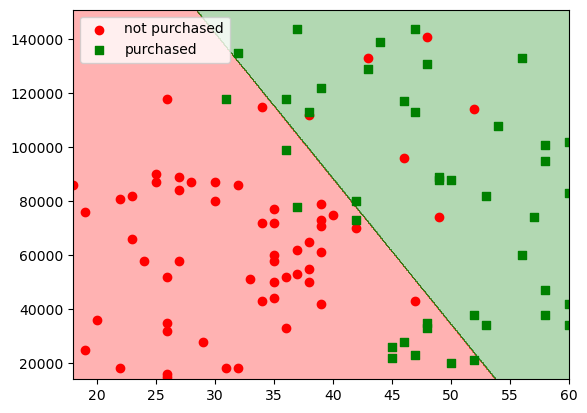

In [71]:
from matplotlib.colors import ListedColormap
class_color = ListedColormap(['red', 'green'])

y_linear = y_linear_grid.reshape(X0.shape)
X0_test = X_test[y_test==0,:]
X1_test = X_test[y_test==1,:]
plt.contourf(X0, X1, y_linear, cmap=class_color, alpha=0.3)
plt.scatter(X0_test[:,0], X0_test[:,1], color='red', label='not purchased')
plt.scatter(X1_test[:,0], X1_test[:,1], color='green', marker='s', label='purchased')
plt.legend()

In [56]:
y_test==0

array([ True,  True, False, False,  True,  True,  True, False,  True,
        True,  True,  True,  True, False, False, False, False,  True,
        True, False,  True, False, False,  True, False,  True, False,
        True, False,  True,  True,  True,  True, False,  True,  True,
        True,  True, False,  True, False, False,  True,  True, False,
       False, False, False,  True, False,  True,  True, False, False,
       False,  True, False,  True, False, False,  True,  True,  True,
        True, False, False,  True,  True,  True,  True,  True,  True,
       False,  True,  True, False,  True,  True,  True,  True,  True,
       False, False,  True,  True,  True, False,  True, False,  True,
       False, False, False,  True,  True, False, False, False,  True,
        True])

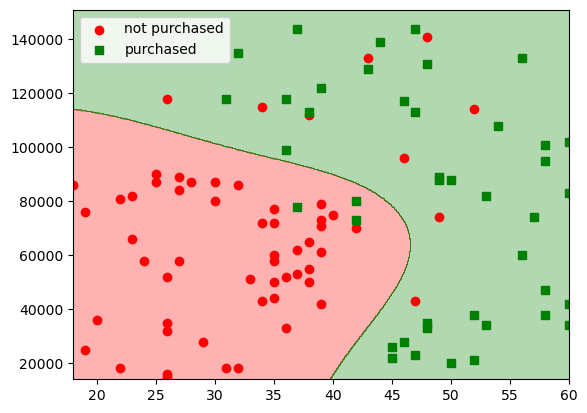

In [72]:
from matplotlib.colors import ListedColormap
class_color = ListedColormap(['red', 'green'])

y_rbf = y_rbf_grid.reshape(X0.shape)
X0_test = X_test[y_test==0,:]
X1_test = X_test[y_test==1,:]
plt.contourf(X0, X1, y_rbf, cmap=class_color, alpha=0.3)
plt.scatter(X0_test[:,0], X0_test[:,1], color='red', label='not purchased')
plt.scatter(X1_test[:,0], X1_test[:,1], color='green', marker='s', label='purchased')
plt.legend()

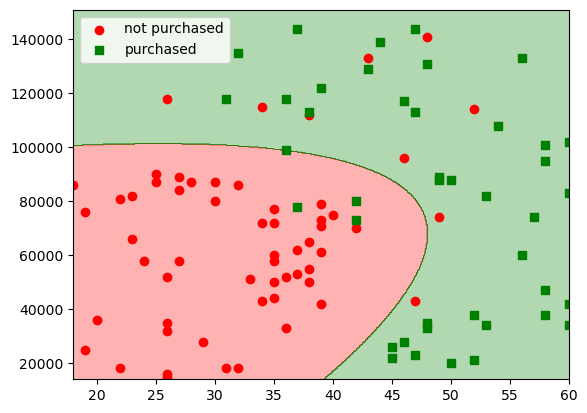

In [73]:
from matplotlib.colors import ListedColormap
class_color = ListedColormap(['red', 'green'])

y_poly = y_poly_grid.reshape(X0.shape)
X0_test = X_test[y_test==0,:]
X1_test = X_test[y_test==1,:]
plt.contourf(X0, X1, y_poly, cmap=class_color, alpha=0.3)
plt.scatter(X0_test[:,0], X0_test[:,1], color='red', label='not purchased')
plt.scatter(X1_test[:,0], X1_test[:,1], color='green', marker='s', label='purchased')
plt.legend()

In [75]:
linear_w = svm_linear.coef_
linear_b = svm_linear.intercept_

In [76]:
sv_rbf = svm_rbf.support_vectors_
alpha_y_rbf = svm_rbf.dual_coef_
blas_rbf = svm_rbf.intercept_

AttributeError: 'SVC' object has no attribute 'dual_coef'